In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
player_data = pd.read_csv(r"C:\Навчання\Програмування\Machine Learning course\player_data.csv")
players = pd.read_csv(r"C:\Навчання\Програмування\Machine Learning course\Players.csv", index_col=0)
seasons_stats = pd.read_csv(r"C:\Навчання\Програмування\Machine Learning course\Seasons_Stats.csv", index_col=0)

In [3]:
player_data.head()

,name,year_start,year_end,position,height,weight,birth_date,college
0,Alaa Abdelnaby,1991,1995,F-C,6-10,240.0,"June 24, 1968",Duke University
1,Zaid Abdul-Aziz,1969,1978,C-F,6-9,235.0,"April 7, 1946",Iowa State University
2,Kareem Abdul-Jabbar,1970,1989,C,7-2,225.0,"April 16, 1947","University of California, Los Angeles"
3,Mahmoud Abdul-Rauf,1991,2001,G,6-1,162.0,"March 9, 1969",Louisiana State University
4,Tariq Abdul-Wahad,1998,2003,F,6-6,223.0,"November 3, 1974",San Jose State University


In [4]:
print(player_data.shape)
player_data.info()

(4550, 8)
<class 'pandas.DataFrame'>
RangeIndex: 4550 entries, 0 to 4549
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        4550 non-null   str    
 1   year_start  4550 non-null   int64  
 2   year_end    4550 non-null   int64  
 3   position    4549 non-null   str    
 4   height      4549 non-null   str    
 5   weight      4544 non-null   float64
 6   birth_date  4519 non-null   str    
 7   college     4248 non-null   str    
dtypes: float64(1), int64(2), str(5)
memory usage: 284.5 KB


In [5]:
#конвертуємо фути в сантиметри
def feet_to_cm(height):
    if pd.isna(height):
        return np.nan
    else:
        feet, inches = map(int, height.split('-'))
        total_inches = 12 * feet + inches
        centimetres = total_inches * 2.54
        return centimetres
player_data['height_cm'] = player_data['height'].apply(feet_to_cm)
player_data['weight_kg'] = player_data['weight'] * 0.4536
player_data['career_dur'] = player_data['year_end'] - player_data['year_start'] # створюємо фічу тривалість кар'єри
player_data['BMI'] = 10000 * player_data['weight_kg']/(player_data['height_cm'])**2
player_data['decade'] = player_data['year_start']//10
player_data


,name,year_start,year_end,position,height,weight,birth_date,college,height_cm,weight_kg,career_dur,BMI,decade
0,Alaa Abdelnaby,1991,1995,F-C,6-10,240.0,"June 24, 1968",Duke University,208.28,108.8640,4,25.095113,199
1,Zaid Abdul-Aziz,1969,1978,C-F,6-9,235.0,"April 7, 1946",Iowa State University,205.74,106.5960,9,25.182766,196
2,Kareem Abdul-Jabbar,1970,1989,C,7-2,225.0,"April 16, 1947","University of California, Los Angeles",218.44,102.0600,19,21.389037,197
3,Mahmoud Abdul-Rauf,1991,2001,G,6-1,162.0,"March 9, 1969",Louisiana State University,185.42,73.4832,10,21.373464,199
4,Tariq Abdul-Wahad,1998,2003,F,6-6,223.0,"November 3, 1974",San Jose State University,198.12,101.1528,5,25.770407,199
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4545,Ante Zizic,2018,2018,F-C,6-11,250.0,"January 4, 1997",NaN,210.82,113.4000,0,25.514640,201
4546,Jim Zoet,1983,1983,C,7-1,240.0,"December 20, 1953",Kent State University,215.90,108.8640,0,23.354953,198
4547,Bill Zopf,1971,1971,G,6-1,170.0,"June 7, 1948",Duquesne University,185.42,77.1120,0,22.428943,197
4548,Ivica Zubac,2017,2018,C,7-1,265.0,"March 18, 1997",NaN,215.90,120.2040,1,25.787761,201


<Axes: ylabel='Density'>

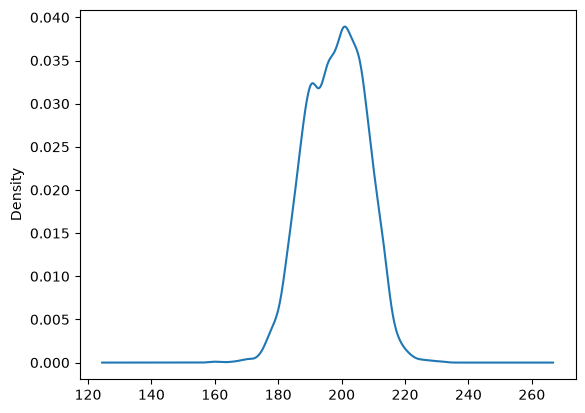

In [6]:
player_data['height_cm'].plot(kind='kde') # хочу перевірити, чи є нормальний розподіл зросту серед учасників

Графік дійсно схожий на нормальний розподіл з невеликим просіданням при зрості ~185-190

<Axes: ylabel='Density'>

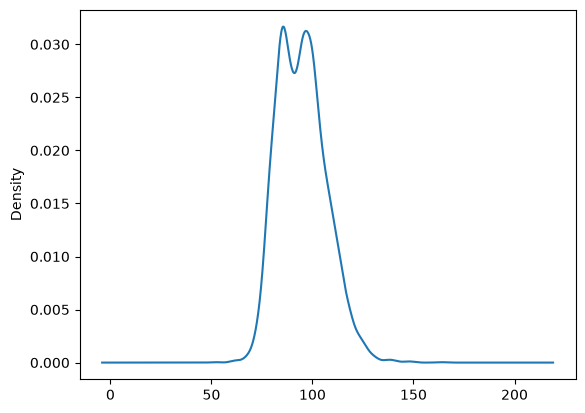

In [7]:
player_data['weight_kg'].plot(kind='kde') # перевіряємо розподіл ваги баскетболістів

Також можемо спостерігати майже нормальний розподіл з двома піками вгорі

<Axes: xlabel='position', ylabel='count'>

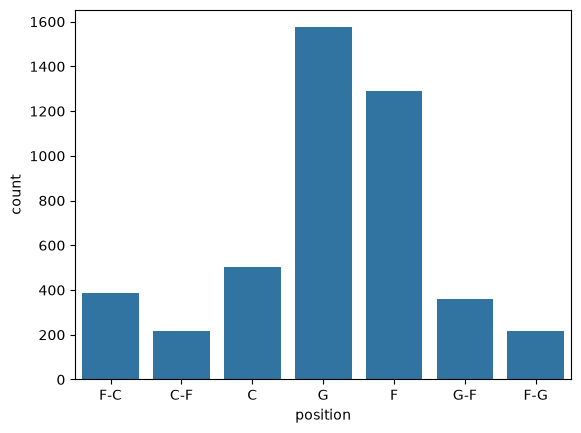

In [8]:
sns.countplot(x='position', data=player_data) # перевіримо, які позиції найчастіше займали гравці

Зі стовпчикової діагарми видно, що найбільше було гравців G та F. Найменше при цьому гравців з позицією C-F

In [9]:
player_data[player_data['position'].isin(['G', 'F'])][['year_start']].value_counts()

year_start
1968          109
1947           93
1971           68
2018           68
2017           64
             ... 
1957           13
1961           13
1965           12
1960           11
1966           10
Name: count, Length: 72, dtype: int64

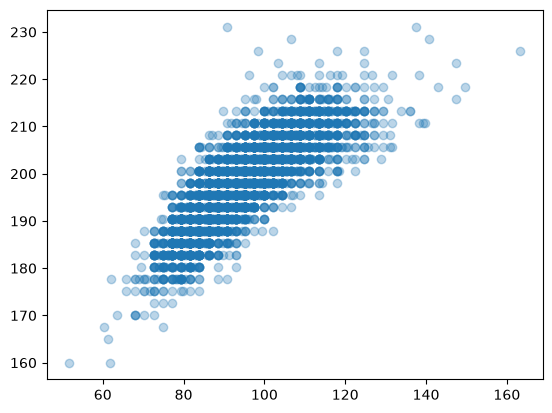

In [10]:
plt.scatter(player_data['weight_kg'], player_data['height_cm'], alpha=0.3) # хочу перевірити, чи є кореляція між вагою та зростом гравців

Оскільки фігура нагадує еліпс, то між зростом і вагою існує кореляція

<Axes: xlabel='decade', ylabel='height_cm'>

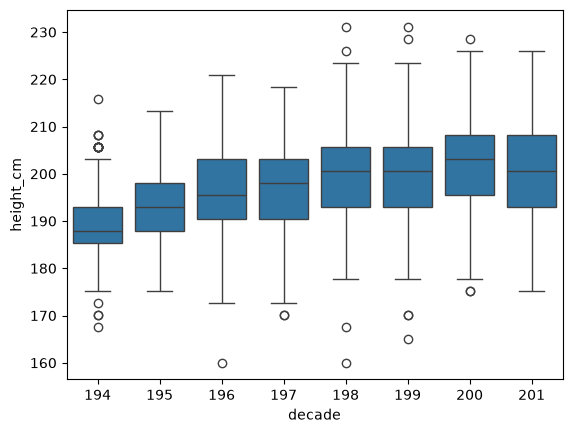

In [11]:
sns.boxplot(x='decade', y='height_cm', data=player_data) # Хочу перевірити розподіл зросту гравців залежно від десятиліття

З діаграми бачимо, що середній зріст учасників загалом ішов на зростання з кожним десятиліттям

In [12]:
players.head()

,Player,height,weight,collage,born,birth_city,birth_state
0,Curly Armstrong,180.0,77.0,Indiana University,1918.0,NaN,NaN
1,Cliff Barker,188.0,83.0,University of Kentucky,1921.0,Yorktown,Indiana
2,Leo Barnhorst,193.0,86.0,University of Notre Dame,1924.0,NaN,NaN
3,Ed Bartels,196.0,88.0,North Carolina State University,1925.0,NaN,NaN
4,Ralph Beard,178.0,79.0,University of Kentucky,1927.0,Hardinsburg,Kentucky


In [13]:
print(players.shape)
players.info()

(3922, 7)
<class 'pandas.DataFrame'>
RangeIndex: 3922 entries, 0 to 3921
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Player       3921 non-null   str    
 1   height       3921 non-null   float64
 2   weight       3921 non-null   float64
 3   collage      3573 non-null   str    
 4   born         3921 non-null   float64
 5   birth_city   3452 non-null   str    
 6   birth_state  3439 non-null   str    
dtypes: float64(3), str(4)
memory usage: 214.6 KB


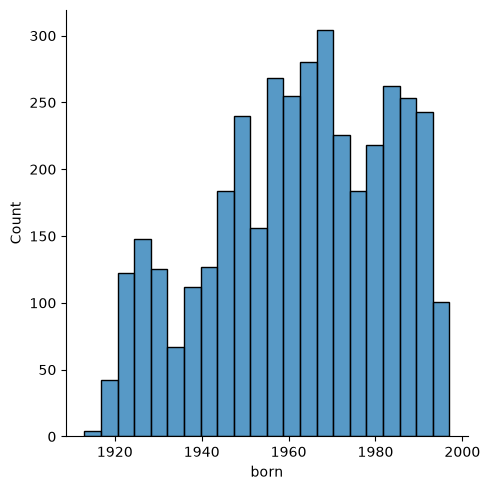

In [14]:
sns.displot(players['born']) # будуємо гістограму з роком народження гравців

Можемо побачити на діаграмі, що було декілька піків з гравцями різного року народження: ~1930, 1950, 1970, 1985. Загалом тенденція вказує на зростання числа учасників до приблизно 1975 року. 

In [15]:
seasons_stats.head()

,Year,Player,Pos,Age,Tm,G,GS,MP,PER,TS%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1950.0,Curly Armstrong,G-F,31.0,FTW,63.0,NaN,NaN,NaN,0.368,...,0.705,NaN,NaN,NaN,176.0,NaN,NaN,NaN,217.0,458.0
1,1950.0,Cliff Barker,SG,29.0,INO,49.0,NaN,NaN,NaN,0.435,...,0.708,NaN,NaN,NaN,109.0,NaN,NaN,NaN,99.0,279.0
2,1950.0,Leo Barnhorst,SF,25.0,CHS,67.0,NaN,NaN,NaN,0.394,...,0.698,NaN,NaN,NaN,140.0,NaN,NaN,NaN,192.0,438.0
3,1950.0,Ed Bartels,F,24.0,TOT,15.0,NaN,NaN,NaN,0.312,...,0.559,NaN,NaN,NaN,20.0,NaN,NaN,NaN,29.0,63.0
4,1950.0,Ed Bartels,F,24.0,DNN,13.0,NaN,NaN,NaN,0.308,...,0.548,NaN,NaN,NaN,20.0,NaN,NaN,NaN,27.0,59.0


In [16]:
print(seasons_stats.shape)
seasons_stats.info()

(24691, 52)
<class 'pandas.DataFrame'>
RangeIndex: 24691 entries, 0 to 24690
Data columns (total 52 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    24624 non-null  float64
 1   Player  24624 non-null  str    
 2   Pos     24624 non-null  str    
 3   Age     24616 non-null  float64
 4   Tm      24624 non-null  str    
 5   G       24624 non-null  float64
 6   GS      18233 non-null  float64
 7   MP      24138 non-null  float64
 8   PER     24101 non-null  float64
 9   TS%     24538 non-null  float64
 10  3PAr    18839 non-null  float64
 11  FTr     24525 non-null  float64
 12  ORB%    20792 non-null  float64
 13  DRB%    20792 non-null  float64
 14  TRB%    21571 non-null  float64
 15  AST%    22555 non-null  float64
 16  STL%    20792 non-null  float64
 17  BLK%    20792 non-null  float64
 18  TOV%    19582 non-null  float64
 19  USG%    19640 non-null  float64
 20  blanl   0 non-null      float64
 21  OWS     24585 non-null  float64
 2

In [17]:
seasons_stats.drop(columns=['blanl', 'blank2'])
seasons_stats['PTS_36'] = seasons_stats['PTS']/seasons_stats['MP'] * 36 # фіча середня кількість очок за 36 хвилин
seasons_stats['AST_to_TOV'] = seasons_stats['AST']/seasons_stats['TOV'] # співвідношення асистів до втрат
seasons_stats['is_modern_era'] = seasons_stats['Year']>1980 # чи епоха сучасного баскетболу
seasons_stats['PPG'] = seasons_stats['PTS']/seasons_stats['G'] # середня кількість очок за гру
seasons_stats

,Year,Player,Pos,Age,Tm,G,GS,MP,PER,TS%,...,AST,STL,BLK,TOV,PF,PTS,PTS_36,AST_to_TOV,is_modern_era,PPG
0,1950.0,Curly Armstrong,G-F,31.0,FTW,63.0,NaN,NaN,NaN,0.368,...,176.0,NaN,NaN,NaN,217.0,458.0,NaN,NaN,False,7.269841
1,1950.0,Cliff Barker,SG,29.0,INO,49.0,NaN,NaN,NaN,0.435,...,109.0,NaN,NaN,NaN,99.0,279.0,NaN,NaN,False,5.693878
2,1950.0,Leo Barnhorst,SF,25.0,CHS,67.0,NaN,NaN,NaN,0.394,...,140.0,NaN,NaN,NaN,192.0,438.0,NaN,NaN,False,6.537313
3,1950.0,Ed Bartels,F,24.0,TOT,15.0,NaN,NaN,NaN,0.312,...,20.0,NaN,NaN,NaN,29.0,63.0,NaN,NaN,False,4.200000
4,1950.0,Ed Bartels,F,24.0,DNN,13.0,NaN,NaN,NaN,0.308,...,20.0,NaN,NaN,NaN,27.0,59.0,NaN,NaN,False,4.538462
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24686,2017.0,Cody Zeller,PF,24.0,CHO,62.0,58.0,1725.0,16.7,0.604,...,99.0,62.0,58.0,65.0,189.0,639.0,13.335652,1.523077,True,10.306452
24687,2017.0,Tyler Zeller,C,27.0,BOS,51.0,5.0,525.0,13.0,0.508,...,42.0,7.0,21.0,20.0,61.0,178.0,12.205714,2.100000,True,3.490196
24688,2017.0,Stephen Zimmerman,C,20.0,ORL,19.0,0.0,108.0,7.3,0.346,...,4.0,2.0,5.0,3.0,17.0,23.0,7.666667,1.333333,True,1.210526
24689,2017.0,Paul Zipser,SF,22.0,CHI,44.0,18.0,843.0,6.9,0.503,...,36.0,15.0,16.0,40.0,78.0,240.0,10.249110,0.900000,True,5.454545


<Axes: xlabel='Year', ylabel='3PAr'>

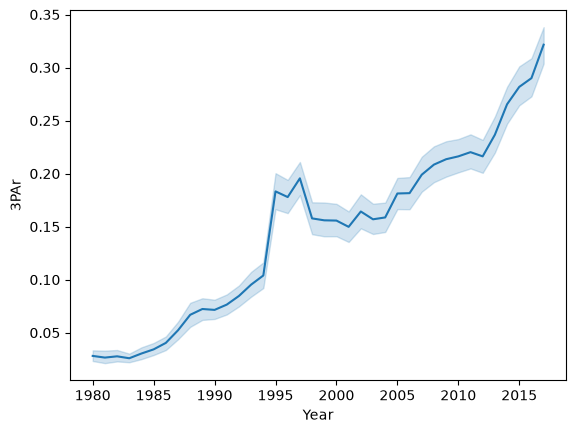

In [18]:
sns.lineplot(x='Year', y='3PAr', data=seasons_stats) # перевіримо середнє значення 3PA впродовж років

Можемо побачити тенденцію, що з роками спроби триочкових йшли на зростання 

<Axes: xlabel='position', ylabel='3PAr'>

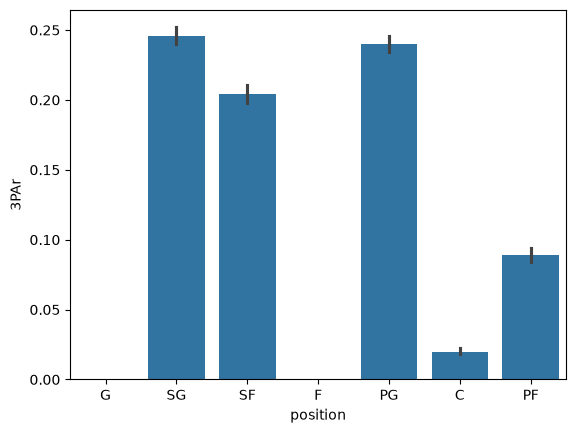

In [19]:
seasons_stats['position'] = seasons_stats['Pos'].str.split('-').str[0] # тепер перевіримо спроби триочкових, в залежності від основних позицій гравців
sns.barplot(x='position', y='3PAr', data=seasons_stats)


Бачимо, що найбільше спроб було в позиції SG, PG та SF

In [21]:
seasons_stats[seasons_stats['position'].isin(['G', 'F'])][['position', '3PAr']].info()

<class 'pandas.DataFrame'>
Index: 482 entries, 0 to 3311
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   position  482 non-null    object 
 1   3PAr      0 non-null      float64
dtypes: float64(1), object(1)
memory usage: 11.3+ KB


<Axes: >

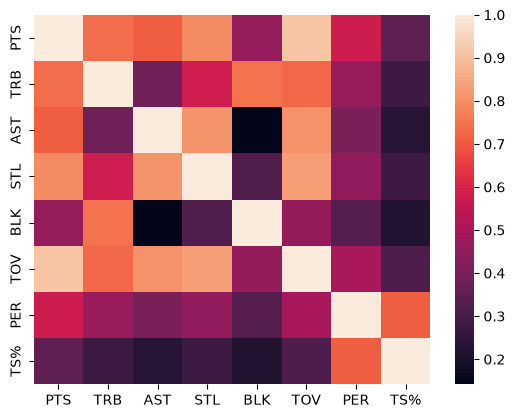

In [22]:
 sns.heatmap(seasons_stats[['PTS', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PER', 'TS%']].corr()) # перевіримо кореляцію основних показників 

Бачимо, що висока кореляція присутня у багатьоз показників, таких як PTS & TRB, PTS & AST, PTS & STL, PTS & TOV та інших. Водночас, низька кореляція у таких показників як, наприклад, BLK & AST, BLK & STL.

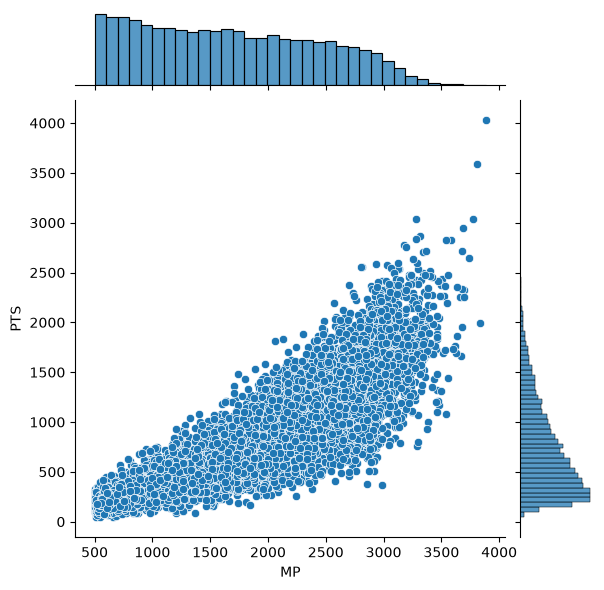

In [23]:
clean_data = seasons_stats[seasons_stats['MP'] > 500] # відсіюємо гравців, які грали мало
sns.jointplot(x='MP', y='PTS', data=clean_data) # первіримо кореляцію між кількістю зіграних хвилин та отриманими очками

Бачимо, що зв'язок є, проте, можливо, він не лінійний